Import des données et des outils

In [23]:
import sys
sys.path.append("..")  

import pandas as pd
import matplotlib.pyplot as plt
from src.cible import episodes 

from src.config import PROCESSED_DIR, START

panel = pd.read_parquet(PROCESSED_DIR / "panel_cible.parquet")
panel = panel.loc[panel.index >= pd.Timestamp(START, tz="UTC")].copy()

Combien d'heures positives pour chaque crypto ? Combien d'épisode de shortsqueeze ?

In [ ]:
for symbole in panel["symbol"].unique():
    panel_crypto = panel.loc[panel["symbol"] == symbole]
    positif = panel_crypto["shortsqueeze"].fillna(False)
    heures_positives = panel_crypto.index[positif].tolist()

    print(symbole, ":", len(heures_positives), "heures positives pour",
          len(episodes(heures_positives)), "épisodes de shortsqueezes")

BTCUSDT : 54 heures positives pour 9 épisodes de shortsqueezes
ETHUSDT : 41 heures positives pour 5 épisodes de shortsqueezes
SOLUSDT : 94 heures positives pour 12 épisodes de shortsqueezes


Moyennes des différentes grandeurs caractérisant les épisodes de shortsqueeze

In [25]:

lignes = []

for symbole in panel["symbol"].unique():
    panel_crypto = panel.loc[panel["symbol"] == symbole]
    positif = panel_crypto["shortsqueeze"].fillna(False)
    heures_positives = panel_crypto.index[positif].tolist()

    for debut, duree in episodes(heures_positives):
        donnees = panel_crypto.loc[debut]

        lignes.append({"symbol": symbole, "debut": debut, "nb_heures_positives": duree,
            "date_pic": donnees["date_pic"], "hausse_pic": donnees["hausse_pic"],
            "variation_oi": donnees["variation_oi"], 
            "ratio_achats_ventes": donnees["ratio_achats_ventes"], 
            "sigma_30j": donnees["sigma_30j"]})

tableau_episodes = pd.DataFrame(lignes)

tableau_episodes_moyennes = tableau_episodes.drop(columns=["date_pic","debut"])
tableau_episodes_moyennes = tableau_episodes_moyennes.groupby("symbol").mean().reset_index()
tableau_episodes_moyennes = tableau_episodes_moyennes.rename(columns={
    "nb_heures_positives": "nb_heures_positives_moyen", "hausse_pic": "hausse_moyenne",
    "variation_oi": "variation_oi_moyenne", 
    "ratio_achats_ventes": "ratio_achats_ventes_moyen", "sigma_30j": "sigma_30j_moyen"})

display(tableau_episodes_moyennes.style.format({
    "hausse_moyenne": "{:.2%}",
    "variation_oi_moyenne": "{:.2%}",
    "ratio_achats_ventes_moyen": "{:.2f}",
    "sigma_30j_moyen": "{:.2%}"
})) 


,symbol,nb_heures_positives_moyen,hausse_moyenne,variation_oi_moyenne,ratio_achats_ventes_moyen,sigma_30j_moyen
0,BTCUSDT,6.000000,12.78%,-10.98%,1.07,0.35%
1,ETHUSDT,8.200000,10.00%,-11.24%,1.09,0.48%
2,SOLUSDT,7.833333,17.42%,-12.29%,1.07,0.88%


Visualisation des shortsqueezes 

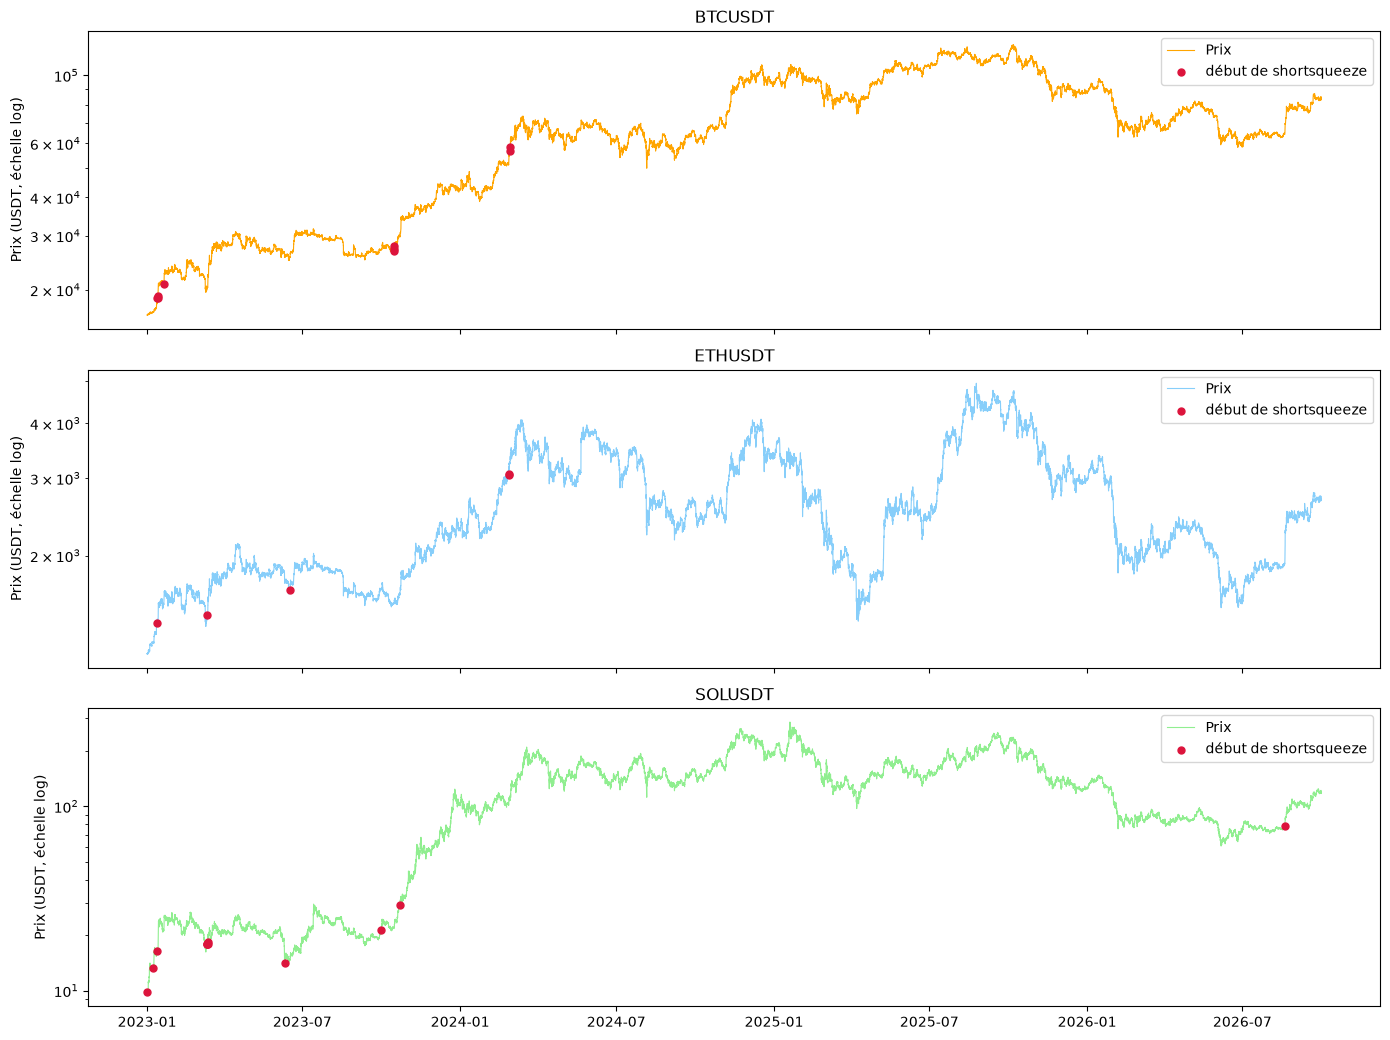

In [26]:
symboles = sorted(panel["symbol"].unique())

fig, axes = plt.subplots(
    len(symboles), 1,
    figsize=(14, 3.5 * len(symboles)),
    sharex=True,
    squeeze=False,
)

couleurs = {"BTCUSDT": "orange", "ETHUSDT": "lightskyblue", "SOLUSDT": "lightgreen"}

for ax, symbole in zip(axes[:, 0], symboles):
    p = panel.loc[panel["symbol"] == symbole].sort_index()
    e = tableau_episodes.loc[tableau_episodes["symbol"] == symbole]

    ax.plot(p.index, p["close"], linewidth=0.8, label="Prix", color=couleurs[symbole])

    ax.scatter(
        e["debut"],
        p["close"].reindex(pd.DatetimeIndex(e["debut"])).to_numpy(),
        color="crimson",
        s=25,
        zorder=3,
        label="début de shortsqueeze",
    )

    ax.set_yscale("log")
    ax.set_title(symbole)
    ax.set_ylabel("Prix (USDT, échelle log)")
    ax.legend()

fig.tight_layout()
plt.show()

In [ ]:
Visualisation du shortsqueeze pour un épisode en particulier

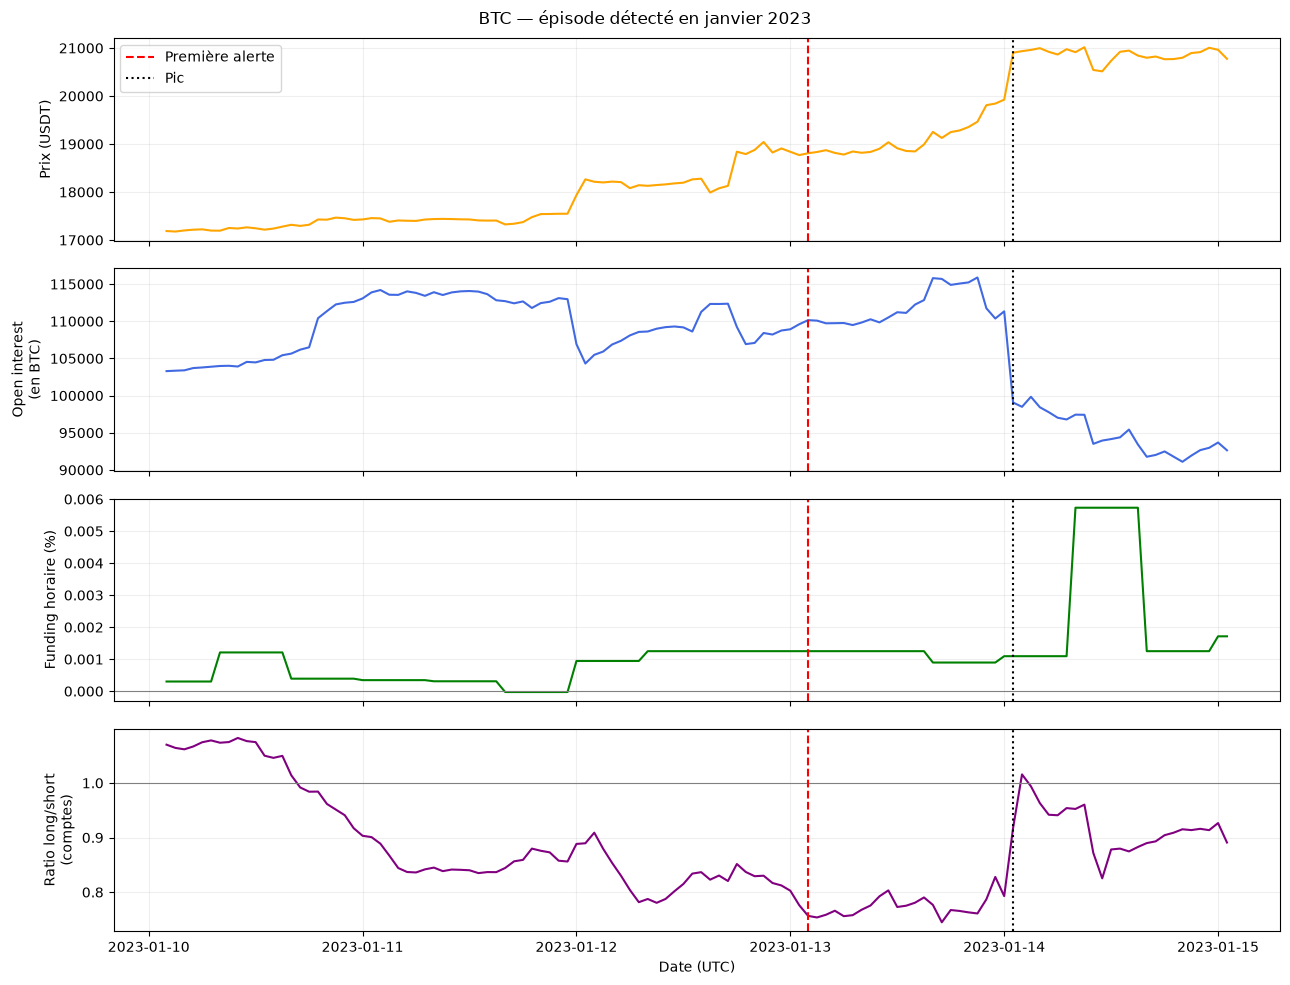

In [ ]:
# Episode étudié : 
symbole = "BTCUSDT"
debut = pd.Timestamp("2023-01-13 02:00", tz="UTC")

p = panel.loc[panel["symbol"] == symbole]
pic = p.loc[debut, "date_pic"]

p = p.loc[debut - pd.Timedelta(days=3): pic + pd.Timedelta(days=1)]

fig, axes = plt.subplots(4, 1, figsize=(13, 10), sharex=True)

axes[0].plot(p.index, p["close"], color="orange")
axes[0].set_ylabel("Prix (USDT)")

axes[1].plot(p.index, p["oi"], color="royalblue")
axes[1].set_ylabel("Open interest\n(en BTC)")

axes[2].plot(p.index, 100 * p["funding_horaire"], color="green")
axes[2].axhline(0, color="grey", linewidth=0.8)
axes[2].set_ylabel("Funding horaire (%)")

axes[3].plot(p.index, p["ls_global"], color="purple")
axes[3].axhline(1, color="grey", linewidth=0.8)
axes[3].set_ylabel("Ratio long/short\n(comptes)")

for ax in axes:
    ax.axvline(debut, color="red", linestyle="--", label="Première alerte")
    ax.axvline(pic, color="black", linestyle=":", label="Pic")
    ax.grid(alpha=0.2)

axes[0].legend()
axes[3].set_xlabel("Date (UTC)")

fig.suptitle("BTC — épisode détecté en janvier 2023")
fig.tight_layout()
plt.show()